In [1]:
import sys
print(sys.executable)
from beir.datasets.data_loader import GenericDataLoader
import pandas as pd

corpus, queries, qrels = GenericDataLoader("../data/scifact").load(split="test")
docs = {did: (d["title"] + ". " + d["text"]).strip() for did, d in corpus.items()}

print("Documents:", len(docs))
print("Queries:", len(queries))
print("Queries with labels:", len(qrels))

d:\search_keyword_semantic\venv\Scripts\python.exe


d:\search_keyword_semantic\venv\Lib\site-packages\beir\datasets\data_loader.py:8: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
100%|██████████| 5183/5183 [00:00<00:00, 122180.44it/s]

Documents: 5183
Queries: 300
Queries with labels: 300


In [2]:
did = next(iter(corpus))
print("ID:   ", did)
print("Title:", corpus[did]["title"])
print("Text: ", corpus[did]["text"][:400], "...")

ID:    4983
Title: Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.
Text:  Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber arch ...


count    5183.000000
mean      214.630909
std        87.287753
min        33.000000
25%       158.000000
50%       204.000000
75%       260.000000
max      1541.000000
dtype: float64


<Axes: >

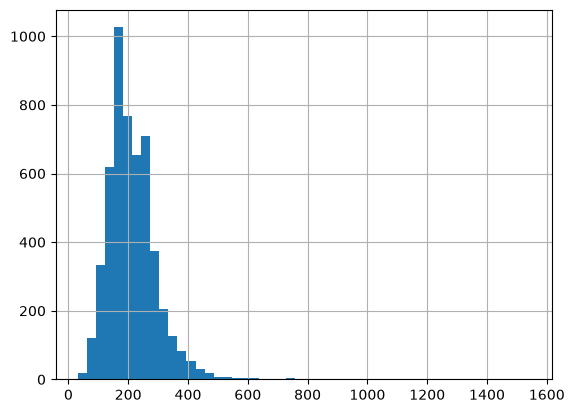

In [3]:
lengths = pd.Series([len(t.split()) for t in docs.values()])
print(lengths.describe())
lengths.hist(bins=50)

In [4]:
qlen = pd.Series([len(q.split()) for q in queries.values()])
print(qlen.describe())

for qid in list(queries)[:5]:
    print(qid, "|", queries[qid])

count    300.000000
mean      12.506667
std        5.141147
min        4.000000
25%        9.000000
50%       12.000000
75%       15.000000
max       29.000000
dtype: float64
1 | 0-dimensional biomaterials show inductive properties.
3 | 1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.
5 | 1/2000 in UK have abnormal PrP positivity.
13 | 5% of perinatal mortality is due to low birth weight.
36 | A deficiency of vitamin B12 increases blood levels of homocysteine.


In [5]:
rel_counts = pd.Series({qid: len(v) for qid, v in qrels.items()})
print(rel_counts.value_counts().sort_index())

1    277
2     14
3      4
4      3
5      2
Name: count, dtype: int64


In [6]:
qid = list(queries)[0]
print("QUERY:", queries[qid], "\n")
for did, rel in qrels[qid].items():
    print("RELEVANCE:", rel)
    print(docs[did][:500], "\n")

QUERY: 0-dimensional biomaterials show inductive properties. 

RELEVANCE: 1
New opportunities: the use of nanotechnologies to manipulate and track stem cells.. Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotubes, and polyplexes for the intracellular delivery of genes/oligonucleotides and protein/peptides; and engineered nanometer-scale scaffolds for stem cell differentiati 

